<a href="https://colab.research.google.com/github/justinliu00/Microstructure-ML-Grain-Diffusion/blob/main/VT_Microstructure_GrainAware_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# VT microstructure model — Grain-aware conditional generation v2

**Goal:** generate multiple **actual image predictions** with sharply separated polygonal grains instead of the washed-out RGB noise of v1. This is an experimental structural redesign, not a validated improvement in physical prediction accuracy.

### What changed

- **Train on grain-distance fields** derived from visible boundaries, rather than arbitrary shuffled grain-ID RGB colors.
- **Conditional diffusion** models spatial morphology conditioned on the thermal field and RPM/MPa/dwell; a separate **training-case-only kNN estimator** predicts overall boundary density.
- A **hard, discrete tessellation** converts each sample to visible, crisp grains; shuffled viridis colors are applied *only for display*. Voronoi polygons are an explicit structural prior, **not evidence that the simulator uses Voronoi grains**.
- **Grain-scale outliers within training cases** are flagged and optionally quarantined, with a CSV audit. **Validation and test records are never automatically deleted as scale outliers.** Non-square image domains are excluded with a report, as in v1.
- Separate validation, test panels, multi-sample outputs, edge/texture metrics, and comparison with nearest training cases. All test seeds count in metrics.

**Important limits:** The screenshots contain shuffled color IDs rather than actual grain-label arrays. Color transitions are only proxies for true boundaries. Exact random grain positions are not identifiable from the given inputs. The dataset has approximately 10 independent conditions (7 train, 1 validation, 2 test in this fixed split); tests previously inspected during development remain exploratory. An improvement in *looking like grains* is not proof of reliable prediction of grain statistics, microphysics, or unseen-process generalization. Obtain the grain-ID arrays, simulator code, and more distinct conditions for a scientific evaluation.

**Old v1 checkpoints cannot be reused:** v2 has a different input representation and network channels. Train once from scratch and use its own checkpoints.

## 1. Install libraries and select GPU

In Colab choose **Runtime → Change runtime type → T4 GPU** (or another GPU), then run cells from top to bottom. This notebook is **self-contained**.

In [9]:
%pip -q install numpy pandas Pillow matplotlib scipy torch
import torch
print('PyTorch:', torch.__version__)
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'None (CPU training will be slow)')

PyTorch: 2.11.0+cu130
GPU: Tesla T4


## 2. Mount Google Drive and locate your original dataset

Put `vt dataset.zip` or `vt dataset(1).zip` in **My Drive**. Output checkpoints and images will be saved under `MyDrive/VT_grain_aware_runs/`.

To resume an interrupted run, set `RESUME=True` and `EXISTING_RUN` to the run folder shown in the first execution. You may increase only `CONFIG["steps"]` when resuming; keep all other configuration and data identical.

In [10]:
from google.colab import drive
from datetime import datetime
from pathlib import Path
import zipfile, tempfile

drive.mount('/content/drive')
ZIP_PATH = Path('/content/drive/MyDrive/vt dataset.zip')
if not ZIP_PATH.exists():
    ZIP_PATH = Path('/content/drive/MyDrive/vt dataset(1).zip')
if not ZIP_PATH.is_file():
    raise FileNotFoundError('Upload your original dataset ZIP to My Drive or edit ZIP_PATH')
RESUME = False
EXISTING_RUN = ''  # Example: '/content/drive/MyDrive/VT_grain_aware_runs/run_20261012_...'

root = Path(tempfile.mkdtemp(prefix='vt_grain_v2_')).resolve()
with zipfile.ZipFile(ZIP_PATH) as archive:
    for member in archive.infolist():
        destination = (root / member.filename).resolve()
        if not destination.is_relative_to(root):
            raise ValueError('ZIP contains an unsafe path')
        if ((member.external_attr >> 16) & 0o170000) == 0o120000:
            raise ValueError('ZIP symlinks are unsupported')
    archive.extractall(root)
found = [p for p in root.rglob('metadata.csv') if '__MACOSX' not in p.parts]
if len(found) != 1:
    raise ValueError('Expected exactly one metadata.csv in the ZIP')
DATA_ROOT = found[0].parent
if RESUME:
    RUN_DIR = Path(EXISTING_RUN)
    if not (RUN_DIR / 'latest.pt').is_file():
        raise FileNotFoundError('Cannot resume: latest.pt was not found')
else:
    RUN_DIR = Path('/content/drive/MyDrive/VT_grain_aware_runs') / datetime.now().strftime('run_%Y%m%d_%H%M%S_%f')
    RUN_DIR.mkdir(parents=True, exist_ok=False)
print('Data directory:', DATA_ROOT)
print('Run directory:', RUN_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Data directory: /tmp/vt_grain_v2_hy2ktgue/dataset
Run directory: /content/drive/MyDrive/VT_grain_aware_runs/run_20261013_011851_732257


## 3. Model implementation — grain-distance diffusion + crisp grain renderer

This cell contains the complete implementation. No external Python file is required in Colab.

In [11]:
"""VT Grain-Aware Conditional Microstructure Generator v2.

Experimental research code. Model outputs crisp discrete grain maps (not blurred RGB).
It combines conditional diffusion of an estimated grain-distance field with a
training-only conditional morphology (edge-density) estimator and discrete
Voronoi tessellation. RGB colors are for visualization, not physical phases.

Limitations: simulator RGB plots are an imperfect proxy for grain IDs; grain
sizes are proxies; small 7-case training split; held-out cases were consulted
in development, so they cannot support an unbiased final accuracy claim.
"""

from __future__ import annotations

import copy
import hashlib
import json
import math
import time
import warnings
from functools import lru_cache
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from scipy import ndimage as ndi
from scipy.spatial import cKDTree
from torch import nn

DEFAULT = dict(
    size=256, width=24, timesteps=200, steps=6000, batch_size=2,
    lr=2e-4, eval_every=300, sample_steps=50, seed=42,
    orientation='x_rows', flip_vertical=False,
    distance_clip=18, edge_threshold=0.10, quarantine_outliers=True,
    outlier_log_ratio=0.85, k_neighbors=2,
)


def safe_path(root, value):
    root = Path(root).resolve()
    p = (root / str(value).replace('\\', '/')).resolve()
    if not p.is_relative_to(root) or not p.is_file():
        raise ValueError(f'Invalid or missing dataset path: {value}')
    return p


def read_thermal(path, size, orientation='x_rows', flip_vertical=False):
    df = pd.read_csv(path)
    if not {'x', 'y', 'temperature'}.issubset(df):
        raise ValueError('Thermal CSV must contain x,y,temperature')
    if not np.isfinite(df[['x', 'y', 'temperature']].to_numpy(float)).all():
        raise ValueError('Nonfinite thermal field')
    if df.duplicated(['x', 'y']).any():
        raise ValueError('Thermal CSV has duplicate x,y; choose one time snapshot')
    a, b = ('x', 'y') if orientation == 'x_rows' else ('y', 'x')
    if orientation not in ('x_rows', 'y_rows'):
        raise ValueError('Unknown orientation')
    g = df.pivot(index=a, columns=b, values='temperature').sort_index().sort_index(axis=1)
    if g.isna().any().any():
        raise ValueError('Thermal CSV does not form a complete grid')
    raw = g.to_numpy(np.float32)
    if flip_vertical:
        raw = raw[::-1].copy()
    t = F.interpolate(torch.tensor(raw.copy())[None, None], (size, size),
                      mode='bilinear', align_corners=False)[0]
    return t


def read_target(path, size):
    with Image.open(path) as im:
        original = np.asarray(im.convert('RGB'))
    chroma = original.max(2).astype(float) - original.min(2).astype(float)
    mask = chroma > 25  # specific to supplied saturated viridis maps on white canvas
    rows = np.flatnonzero(mask.mean(1) > .1)
    cols = np.flatnonzero(mask.mean(0) > .1)
    if not len(rows) or not len(cols):
        raise ValueError(f'Cannot identify plot color domain: {path}')
    box = [int(cols[0]), int(rows[0]), int(cols[-1] + 1), int(rows[-1] + 1)]
    crop = original[box[1]:box[3], box[0]:box[2]]
    if min(crop.shape[:2]) < 32:
        raise ValueError('Microstructure target smaller than 32 pixels')
    arr = np.asarray(Image.fromarray(crop).resize((size, size), Image.Resampling.NEAREST)).copy()
    return arr, box


def texture_stats(rgb, threshold=.10):
    a = np.asarray(rgb, dtype=np.float32)
    if a.max() > 1.5:
        a = a / 255.0
    dx = np.linalg.norm(a[:, 1:] - a[:, :-1], axis=2)
    dy = np.linalg.norm(a[1:] - a[:-1], axis=2)
    result = dict(color_std=float(a.std(axis=(0, 1)).mean()),
                  edge_fraction=float(((dx > threshold).mean() + (dy > threshold).mean()) / 2))
    for lag in (1, 4, 16):
        result[f'color_difference_lag{lag}'] = float(np.abs(a[:, lag:] - a[:, :-lag]).mean())
    return result


def boundary_mask(rgb, threshold=.10):
    a = rgb.astype(np.float32) / 255.0
    right = np.linalg.norm(a[:, 1:] - a[:, :-1], axis=-1) > threshold
    down = np.linalg.norm(a[1:] - a[:-1], axis=-1) > threshold
    b = np.zeros(a.shape[:2], dtype=bool)
    b[:, :-1] |= right
    b[1:, :] |= down
    return b


def grain_distance(rgb, clip=18, threshold=.10):
    """Estimate distance to a visible color transition (NOT true grain IDs)."""
    edges = boundary_mask(rgb, threshold)
    d = ndi.distance_transform_edt(~edges).astype(np.float32)
    d = np.clip(d, 0, clip) / clip
    return (2 * d - 1)[None].astype(np.float32)


def _choose_majority_outliers(rows, threshold):
    """Only flag unambiguous minority modes with >2x edge-density disparity."""
    x = np.log(np.maximum(np.asarray(rows, float), 1e-5))
    if len(x) < 4:
        return np.zeros(len(x), bool)
    m = np.median(x)
    hits = np.abs(x - m) <= threshold
    if hits.sum() < 3 or hits.sum() <= len(x) / 2:
        return np.zeros(len(x), bool)
    return ~hits


def prepare(root, cfg):
    root = Path(root)
    meta = pd.read_csv(root / 'metadata.csv')
    needed = {'case', 'thermal_history_path', 'microstructure_path', 'rpm', 'mpa', 'dwell'}
    if not needed.issubset(meta.columns):
        raise ValueError(f'Missing dataset metadata columns: {needed - set(meta.columns)}')
    if meta[list(needed)].isna().any().any():
        raise ValueError('Metadata missing case, path or process values')
    unique = np.sort(meta.case.unique())
    if len(unique) < 4:
        raise ValueError('Need >=4 independent process cases')
    rng = np.random.default_rng(cfg['seed'])
    perm = rng.permutation(unique)
    n_train = min(max(2, int(.7 * len(perm))), len(perm) - 2)
    n_val = 1 if len(perm) < 20 else max(1, int(.1 * len(perm)))
    split = dict(train=perm[:n_train].tolist(), val=perm[n_train:n_train+n_val].tolist(),
                 test=perm[n_train+n_val:].tolist())
    raw, therm, proc, targets, fields, boxes, kept, excluded = [], [], [], [], [], [], [], []
    cache = {}
    for i, row in meta.iterrows():
        arr, box = read_target(safe_path(root, row['microstructure_path']), cfg['size'])
        aspect = (box[2] - box[0]) / (box[3] - box[1])
        if not .9 < aspect < 1.1:
            excluded.append(dict(path=row['microstructure_path'], case=row['case'],
                                 reason='Non-square colored domain; unknown physical mapping', aspect=aspect))
            continue
        p = row['thermal_history_path']
        if p not in cache:
            cache[p] = read_thermal(safe_path(root, p), cfg['size'], cfg['orientation'], cfg['flip_vertical'])
        kept.append(i)
        raw.append(cache[p])
        proc.append([row.rpm, row.mpa, row.dwell])
        targets.append(arr)
        fields.append(grain_distance(arr, cfg['distance_clip'], cfg['edge_threshold']))
        boxes.append(box)
    meta = meta.iloc[kept].reset_index(drop=True)
    thermal_raw = torch.stack(raw)
    process_raw = torch.tensor(proc, dtype=torch.float32)
    if not torch.isfinite(process_raw).all():
        raise ValueError('Nonfinite RPM/MPa/dwell')
    indices = {k: np.flatnonzero(meta.case.isin(v).to_numpy()) for k, v in split.items()}
    if any(len(v) == 0 for v in indices.values()):
        raise ValueError('Empty case group after invalid-domain exclusions')
    tr = indices['train']
    owners = {}
    for label, ids in indices.items():
        for i in ids:
            key = hashlib.sha256(thermal_raw[i].numpy().tobytes() + process_raw[i].numpy().tobytes()).hexdigest()
            if key in owners and owners[key] != label:
                raise ValueError('Input leakage across grouped cases')
            owners[key] = label
    norm = dict(tmean=float(thermal_raw[tr].mean()), tstd=max(float(thermal_raw[tr].std()), 1e-6),
                pmean=process_raw[tr].mean(0).tolist(),
                pstd=process_raw[tr].std(0).clamp_min(1e-6).tolist(),
                pmin=process_raw[tr].amin(0).tolist(), pmax=process_raw[tr].amax(0).tolist(),
                tmin=float(thermal_raw[tr].min()), tmax=float(thermal_raw[tr].max()))
    proc_norm = (process_raw - torch.tensor(norm['pmean'])) / torch.tensor(norm['pstd'])
    temp_norm = (thermal_raw - norm['tmean']) / norm['tstd']
    metrics = []
    for i, (row, img) in enumerate(zip(meta.itertuples(), targets)):
        metrics.append(dict(index=i, case=row.case, path=row.microstructure_path,
                            split=next(k for k, v in indices.items() if i in v),
                            **texture_stats(img, cfg['edge_threshold'])))
    audit = pd.DataFrame(metrics)
    audit['quarantined_from_training'] = False
    # Only training images may be quarantined; val/test always evaluated in full.
    for case in split['train']:
        rows = audit.index[(audit.case == case) & (audit.split == 'train')].to_numpy()
        flagged = _choose_majority_outliers(audit.loc[rows, 'edge_fraction'].to_numpy(), cfg['outlier_log_ratio'])
        if cfg['quarantine_outliers']:
            audit.loc[rows[flagged], 'quarantined_from_training'] = True
    effective = tr[~audit.loc[tr, 'quarantined_from_training'].to_numpy()]
    if len(effective) == 0:
        raise ValueError('No training records after audit')
    fingerprint = hashlib.sha256()
    fingerprint.update(meta.to_csv(index=False).encode())
    fingerprint.update(np.stack(targets).tobytes())
    fingerprint.update(thermal_raw.numpy().tobytes())
    fingerprint.update(process_raw.numpy().tobytes())
    fingerprint.update(effective.tobytes())
    return dict(fingerprint=fingerprint.hexdigest(), meta=meta, targets=targets, thermal=temp_norm, process=proc_norm,
                thermal_raw=thermal_raw, process_raw=process_raw,
                distance=torch.tensor(np.stack(fields)), split=split, indices=indices,
                train_indices=effective, audit=audit, norm=norm, boxes=boxes, excluded=excluded,
                config=dict(cfg))


class Block(nn.Module):
    def __init__(self, ci, co):
        super().__init__()
        self.a = nn.Conv2d(ci, co, 3, padding=1)
        self.b = nn.Conv2d(co, co, 3, padding=1)
        self.n1 = nn.GroupNorm(8 if co % 8 == 0 else 4, co)
        self.n2 = nn.GroupNorm(8 if co % 8 == 0 else 4, co)
        self.emb = nn.Linear(128, 2 * co)
        self.skip = nn.Conv2d(ci, co, 1) if ci != co else nn.Identity()

    def forward(self, x, emb):
        h = F.silu(self.n1(self.a(x)))
        scale, bias = self.emb(emb).chunk(2, dim=1)
        h = self.n2(self.b(h)) * (1 + scale[..., None, None]) + bias[..., None, None]
        return F.silu(h + self.skip(x))


class MorphologyDenoiser(nn.Module):
    """Conditional diffusion of scalar visible-grain distance fields."""
    def __init__(self, width=24):
        super().__init__()
        w = width
        self.register_buffer('freq', torch.exp(-math.log(10000) * torch.arange(32) / 31))
        self.time = nn.Sequential(nn.Linear(64, 128), nn.SiLU(), nn.Linear(128, 128))
        self.proc = nn.Sequential(nn.Linear(3, 128), nn.SiLU(), nn.Linear(128, 128))
        self.e1 = Block(2, w)
        self.e2 = Block(w, 2*w)
        self.e3 = Block(2*w, 4*w)
        self.mid = Block(4*w, 8*w)
        self.d3 = Block(12*w, 4*w)
        self.d2 = Block(6*w, 2*w)
        self.d1 = Block(3*w, w)
        self.out = nn.Conv2d(w, 1, 1)

    def forward(self, x, t, thermal, process):
        z = t.float()[:, None] * self.freq[None]
        emb = self.time(torch.cat([z.sin(), z.cos()], dim=1)) + self.proc(process)
        a = self.e1(torch.cat([x, thermal], 1), emb)
        b = self.e2(F.avg_pool2d(a, 2), emb)
        c = self.e3(F.avg_pool2d(b, 2), emb)
        h = self.mid(F.avg_pool2d(c, 2), emb)
        for skip, layer in ((c, self.d3), (b, self.d2), (a, self.d1)):
            h = layer(torch.cat([F.interpolate(h, size=skip.shape[-2:], mode='nearest'), skip], 1), emb)
        return self.out(h)


def noise_schedule(steps, device):
    u = torch.linspace(0, steps, steps+1, device=device, dtype=torch.float64) / steps
    abar = torch.cos((u + .008) / 1.008 * math.pi / 2).square()
    abar /= abar[0].clone()
    beta = (1 - abar[1:] / abar[:-1]).clamp(1e-5, .999).float()
    return torch.cumprod(1 - beta, dim=0)


def diffusion_loss(net, gt, thermal, proc, t, eps, alpha):
    a = alpha[t][:, None, None, None]
    corrupted = a.sqrt() * gt + (1-a).sqrt() * eps
    estimated_noise = net(corrupted, t, thermal, proc)
    noise_mse = F.mse_loss(estimated_noise, eps)
    # Structural reconstruction is only applied at low-noise timesteps.
    selected = t < max(2, len(alpha) // 4)
    if selected.any():
        rec = ((corrupted[selected] - (1-a[selected]).sqrt()*estimated_noise[selected])
               / a[selected].sqrt()).clamp(-1, 1)
        target = gt[selected]
        geom = F.smooth_l1_loss(rec, target)
        grad = F.l1_loss(rec[:, :, :, 1:] - rec[:, :, :, :-1],
                         target[:, :, :, 1:] - target[:, :, :, :-1])
        grad += F.l1_loss(rec[:, :, 1:, :] - rec[:, :, :-1, :],
                          target[:, :, 1:, :] - target[:, :, :-1, :])
        total = noise_mse + .15*geom + .03*grad
    else:
        total = noise_mse
    return total, noise_mse


def train(data, cfg, out, resume=False):
    out = Path(out)
    out.mkdir(parents=True, exist_ok=True)
    torch.manual_seed(cfg['seed'])
    rng = np.random.default_rng(cfg['seed'])
    dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    net = MorphologyDenoiser(cfg['width']).to(dev)
    ema = copy.deepcopy(net).eval()
    optim = torch.optim.AdamW(net.parameters(), lr=cfg['lr'], weight_decay=1e-4)
    history, start, best = [], 0, float('inf')
    ckpt_latest = out / 'latest.pt'
    if resume:
        ck = torch.load(ckpt_latest, map_location=dev, weights_only=False)
        old_cfg = dict(ck['config'])
        new_cfg = dict(cfg)
        old_total, new_total = old_cfg.pop('steps'), new_cfg.pop('steps')
        if (old_cfg != new_cfg or ck['split'] != data['split'] or
                ck.get('fingerprint') != data['fingerprint'] or new_total < old_total):
            raise ValueError('Resume requires identical data/config except a larger total step count.')
        net.load_state_dict(ck['model'])
        ema.load_state_dict(ck['ema'])
        optim.load_state_dict(ck['optimizer'])
        history, start, best = ck['history'], ck['step'], ck['best']
        rng.bit_generator.state = ck['numpy_rng']
        torch.set_rng_state(ck['torch_rng'].cpu())
        if dev.type == 'cuda' and ck['cuda_rng'] is not None:
            torch.cuda.set_rng_state_all([s.cpu() for s in ck['cuda_rng']])
    elif ckpt_latest.exists():
        raise ValueError('Run folder has a checkpoint. Choose resume=True or a fresh folder.')
    alpha = noise_schedule(cfg['timesteps'], dev)
    tr = data['train_indices']
    val = data['indices']['val']
    gen = torch.Generator().manual_seed(2718)
    t_val = torch.randint(cfg['timesteps'], (len(val),), generator=gen)
    eps_val = torch.randn(data['distance'][val].shape, generator=gen)
    began = time.time()
    for step in range(start + 1, cfg['steps'] + 1):
        net.train()
        ids = rng.choice(tr, size=cfg['batch_size'], replace=True)
        y = data['distance'][ids].to(dev)
        th = data['thermal'][ids].to(dev)
        pr = data['process'][ids].to(dev)
        t = torch.randint(cfg['timesteps'], (len(ids),), device=dev)
        eps = torch.randn_like(y)
        loss, nmse = diffusion_loss(net, y, th, pr, t, eps, alpha)
        if not torch.isfinite(loss):
            raise RuntimeError('Training loss is NaN/Inf')
        optim.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(net.parameters(), 1.0)
        optim.step()
        decay = min(.995, (1+step) / (10+step))
        with torch.no_grad():
            for dst, src in zip(ema.parameters(), net.parameters()):
                dst.lerp_(src, 1-decay)
        if step == 1 or step % cfg['eval_every'] == 0 or step == cfg['steps']:
            vals = []
            with torch.no_grad():
                for j, i in enumerate(val):
                    z = data['distance'][i:i+1].to(dev)
                    _, mse = diffusion_loss(ema, z, data['thermal'][i:i+1].to(dev),
                                            data['process'][i:i+1].to(dev),
                                            t_val[j:j+1].to(dev), eps_val[j:j+1].to(dev), alpha)
                    vals.append(float(mse))
            validation = float(np.mean(vals))
            improved = validation < best
            best = min(best, validation)
            history.append(dict(step=step, train_noise_mse=float(nmse.detach()),
                                val_noise_mse=validation, train_total_loss=float(loss.detach())))
            ck = dict(model=net.state_dict(), ema=ema.state_dict(), optimizer=optim.state_dict(),
                      step=step, best=best, history=history, config=cfg, split=data['split'],
                      fingerprint=data['fingerprint'],
                      norm=data['norm'], numpy_rng=rng.bit_generator.state,
                      torch_rng=torch.get_rng_state(),
                      cuda_rng=torch.cuda.get_rng_state_all() if dev.type == 'cuda' else None)
            torch.save(ck, ckpt_latest)
            if improved:
                torch.save(ck, out / 'best.pt')
            pd.DataFrame(history).to_csv(out / 'training_history.csv', index=False)
            print(f'Step {step}/{cfg["steps"]} | train noise MSE {float(nmse.detach()):.4f} | '
                  f'val noise MSE {validation:.4f} | {(time.time()-began)/60:.1f} min', flush=True)
    return out / 'best.pt'


def load_model(checkpoint):
    dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    ck = torch.load(checkpoint, map_location=dev, weights_only=False)  # trusted own files only
    model = MorphologyDenoiser(ck['config']['width']).to(dev).eval()
    model.load_state_dict(ck['ema'])
    return model, ck


@torch.inference_mode()
def sample_distance(model, thermal, process, total_steps, sample_steps=50, seed=123):
    """DDIM sampling with a reduced schedule: final single-channel distance map."""
    dev = next(model.parameters()).device
    thermal, process = thermal.to(dev), process.to(dev)
    gen = torch.Generator(device=dev).manual_seed(int(seed))
    x = torch.randn((len(thermal), 1, *thermal.shape[-2:]), device=dev, generator=gen)
    a = noise_schedule(total_steps, dev)
    sched = torch.linspace(total_steps-1, 0, min(sample_steps, total_steps), device=dev).long()
    for j, i in enumerate(sched):
        ts = torch.full((len(x),), int(i), device=dev, dtype=torch.long)
        ai = a[i]
        predicted_eps = model(x, ts, thermal, process)
        x0 = ((x - (1-ai).sqrt()*predicted_eps) / ai.sqrt()).clamp(-1, 1)
        if j+1 < len(sched):
            ap = a[sched[j+1]]
            x = ap.sqrt()*x0 + (1-ap).sqrt()*predicted_eps
        else:
            x = x0
    return x.cpu().numpy()


def _input_case_distances(data, thermal, process):
    """Process/field distance, training cases only. Same principle as v1 baseline."""
    rows = []
    for case in data['split']['train']:
        ids = [i for i in data['train_indices'] if data['meta'].iloc[i].case == case]
        if not ids:
            continue
        idx = ids[0]
        d = float((data['process'][idx] - process).square().mean() +
                  (data['thermal'][idx] - thermal).square().mean())
        rows.append((case, d, idx))
    return sorted(rows, key=lambda x: x[1])


def predict_edge_density(data, thermal, process, k=2):
    """Case-level kNN log-edge-density; avoids pretending random grain IDs are predictable."""
    cases = _input_case_distances(data, thermal, process)
    if not cases:
        raise ValueError('No usable training case reference')
    selected = cases[:min(k, len(cases))]
    log_edges = []
    for case, _, _ in selected:
        ids = [i for i in data['train_indices'] if data['meta'].iloc[i].case == case]
        values = data['audit'].loc[ids, 'edge_fraction'].to_numpy(float)
        log_edges.append(float(np.median(np.log(np.maximum(values, 1e-5)))))
    dist = np.array([c[1] for c in selected])
    if dist[0] < 1e-9:
        weight = np.zeros(len(dist)); weight[0] = 1
    else:
        # Favor nearest case strongly, while allowing interpolation to the next case.
        weight = 1 / (dist + 1e-3)**2
        weight = weight / weight.sum()
    expected = float(np.exp(weight @ np.asarray(log_edges)))
    return np.clip(expected, .005, .90), selected


def make_grain_labels(size, n, rng, morphology_field=None, lloyd=True):
    """Generate hard grain membership via a discrete, stochastic spatial tessellation."""
    h = w = size
    n = int(np.clip(n, 8, size*size//2))
    if morphology_field is None:
        field = None
    else:
        field = np.asarray(morphology_field, float).reshape(size, size)
        if not np.isfinite(field).all():
            field = None
    if field is None or field.std() < 1e-4:
        weight = None
    else:
        # Learned morphology guides placement, but does not determine the entire pattern.
        sig = 1.8 if n < 3000 else .65
        blurred = ndi.gaussian_filter(field, sig)
        z = (blurred - blurred.mean()) / max(blurred.std(), 1e-3)
        wt = np.exp(np.clip(.35*z, -1.2, 1.2))
        weight = (wt / wt.sum()).ravel()
    chosen = rng.choice(size*size, n, replace=False, p=weight)
    seed_y, seed_x = np.divmod(chosen, size)
    seeds = np.column_stack([seed_y, seed_x]).astype(np.float32) + rng.uniform(-.45, .45, (n, 2))
    ys, xs = np.mgrid[:size, :size]
    pixels = np.column_stack([ys.ravel(), xs.ravel()])
    labels = cKDTree(seeds).query(pixels, k=1, workers=1)[1]
    if lloyd and n <= 8000:
        cnt = np.bincount(labels, minlength=n).clip(min=1)
        cent_y = np.bincount(labels, weights=pixels[:, 0], minlength=n)/cnt
        cent_x = np.bincount(labels, weights=pixels[:, 1], minlength=n)/cnt
        centers = .55*seeds + .45*np.column_stack([cent_y, cent_x])
        labels = cKDTree(centers).query(pixels, k=1, workers=1)[1]
    return labels.reshape(size, size), n


def paint_labels(labels, rng):
    # Grain IDs are arbitrary; use shuffled viridis purely for visualization.
    n = int(labels.max()) + 1
    viridis = plt.get_cmap('viridis')
    colors = (viridis(rng.uniform(.01, .99, n))[:, :3] * 255).round().astype(np.uint8)
    return colors[labels]


@lru_cache(maxsize=8)
def density_calibration(size, threshold):
    """Empirically map expected discontinuity fraction to a Voronoi grain count."""
    candidates = np.unique(np.geomspace(12, min(size*size//2, 25000), 19).astype(int))
    densities = []
    for i, n in enumerate(candidates):
        rg = np.random.default_rng(30000+i)
        labels, _ = make_grain_labels(size, n, rg, lloyd=True)
        img = paint_labels(labels, rg)
        densities.append(texture_stats(img, threshold)['edge_fraction'])
    # Minor stochastic non-monotonicity is removed for interpolation.
    p = np.maximum.accumulate(densities)
    return np.asarray(candidates), np.asarray(p)


def density_to_count(p, size, threshold=.10):
    ns, densities = density_calibration(size, threshold)
    # Interpolate on log count; clamp if extrapolating outside calibrated range.
    return int(round(np.exp(np.interp(p, densities, np.log(ns)))))


def generate_images(model, data, thermal, process, n_samples=4, seed=2026):
    """Generate genuinely new tessellations conditioned on input morphology priors."""
    cfg = data['config']
    estimated_p, neighbors = predict_edge_density(data, thermal[0], process[0], cfg['k_neighbors'])
    count = density_to_count(estimated_p, cfg['size'], cfg['edge_threshold'])
    images = []
    maps = []
    for s in range(n_samples):
        random_seed = int(seed) + s
        field = (sample_distance(model, thermal, process, cfg['timesteps'], cfg['sample_steps'], random_seed)[0, 0]
                 if model is not None else None)
        rng = np.random.default_rng(random_seed)
        labels, n = make_grain_labels(cfg['size'], count, rng, field)
        img = paint_labels(labels, rng)
        images.append(img)
        maps.append(dict(seed=random_seed, predicted_edge_density=estimated_p, number_of_grain_sites=n,
                         nearest_training_cases=[str(c[0]) for c in neighbors]))
    return images, maps


def _save_rgb(path, rgb):
    Image.fromarray(rgb.astype('uint8'), 'RGB').save(path)


def evaluate_images(data, checkpoint, out, n_samples=4):
    out = Path(out)
    out.mkdir(parents=True, exist_ok=True)
    model, ck = load_model(checkpoint)
    if ck.get('fingerprint') != data['fingerprint']:
        raise ValueError('Evaluation data bank does not match checkpoint')
    rows, panels, reports = [], [], []
    threshold = data['config']['edge_threshold']
    for case in data['split']['test']:
        ids = np.flatnonzero(data['meta'].case.to_numpy() == case)
        ref = ids[0]
        imgs, diagnostics = generate_images(model, data, data['thermal'][ref:ref+1],
                                             data['process'][ref:ref+1], n_samples, 1000+int(case)*100)
        neighbors = _input_case_distances(data, data['thermal'][ref], data['process'][ref])
        nearest_idx = neighbors[0][2]
        baseline = data['targets'][nearest_idx]
        for s, img in enumerate(imgs):
            _save_rgb(out / f'case_{case}_grain_prediction_{s+1}.png', img)
            rows.append(dict(case=case, source='grain_aware_v2', sample=s+1,
                             **texture_stats(img, threshold)))
        # All actual test seeds participate in the statistics, not just seed 1.
        for s, i in enumerate(ids):
            rows.append(dict(case=case, source='target', sample=s+1,
                             **texture_stats(data['targets'][i], threshold)))
        rows.append(dict(case=case, source='nearest_training_case', sample=1,
                         **texture_stats(baseline, threshold)))
        predicted_edge = diagnostics[0]['predicted_edge_density']
        reports.append(dict(case=case, predicted_edge_density=predicted_edge,
                            inferred_site_count=diagnostics[0]['number_of_grain_sites'],
                            actual_target_edge_densities=[float(texture_stats(data['targets'][i], threshold)['edge_fraction']) for i in ids],
                            nearest_training_case=neighbors[0][0]))
        panels.append((case, data['targets'][ref], imgs, baseline))
    fig, axes = plt.subplots(len(panels), n_samples+2, figsize=(2.8*(n_samples+2), 3*len(panels)), squeeze=False)
    for r, (case, target, imgs, baseline) in enumerate(panels):
        entries = [target]+imgs+[baseline]
        labels = ['Target (one seed)']+[f'Grain-aware sample {s+1}' for s in range(n_samples)]+['Nearest training case']
        for ax, img, label in zip(axes[r], entries, labels):
            ax.imshow(img)
            ax.axis('off')
            ax.set_title(f'Case {case}\n{label}', fontsize=9)
    fig.suptitle('Grain-aware conditional samples | grain IDs/positions not identifiable', fontsize=12)
    fig.tight_layout()
    fig.savefig(out/'image_predictions_v2.png', dpi=145)
    plt.close(fig)
    df = pd.DataFrame(rows)
    df.to_csv(out/'morphology_metrics_per_image.csv', index=False)
    metrics = df.groupby(['case', 'source']).mean(numeric_only=True).drop(columns='sample')
    metrics.to_csv(out/'morphology_metrics_summary.csv')
    score_rows = []
    for case in data['split']['test']:
        sub = df[df.case == case]
        true = sub[sub.source == 'target']['edge_fraction'].mean()
        for name in ('grain_aware_v2', 'nearest_training_case'):
            pred = sub[sub.source == name]['edge_fraction'].mean()
            score_rows.append(dict(case=case, source=name, target_mean_edge_fraction=true,
                                   predicted_mean_edge_fraction=pred, absolute_edge_fraction_error=abs(pred-true)))
    pd.DataFrame(score_rows).to_csv(out/'edge_density_scorecard.csv', index=False)
    (out/'test_diagnostics.json').write_text(json.dumps(reports, indent=2, default=str))
    return metrics


def predict_new(data, checkpoint, thermal_csv, rpm, mpa, dwell, out, n_samples=4, seed=2026):
    model, ck = load_model(checkpoint)
    if ck.get('fingerprint') != data['fingerprint']:
        raise ValueError('Prediction dataset differs from the trained checkpoint bank')
    cfg, norm = ck['config'], ck['norm']
    out = Path(out)
    out.mkdir(parents=True, exist_ok=True)
    process = torch.tensor([[rpm, mpa, dwell]], dtype=torch.float32)
    if not torch.isfinite(process).all():
        raise ValueError('Nonfinite process inputs')
    if ((process < torch.tensor(norm['pmin'])) | (process > torch.tensor(norm['pmax']))).any():
        warnings.warn('New process values lie outside training range; extrapolation is unvalidated')
    temperature = read_thermal(thermal_csv, cfg['size'], cfg['orientation'], cfg['flip_vertical'])[None]
    if temperature.min() < norm['tmin'] or temperature.max() > norm['tmax']:
        warnings.warn('New thermal field exceeds training range')
    thermal = (temperature - norm['tmean']) / norm['tstd']
    process = (process - torch.tensor(norm['pmean'])) / torch.tensor(norm['pstd'])
    images, report = generate_images(model, data, thermal, process, n_samples, seed)
    for j, img in enumerate(images):
        _save_rgb(out / f'prediction_seed_{seed+j}.png', img)
    (out/'prediction_metadata.json').write_text(json.dumps(report, indent=2))
    return images


def save_audit(data, out):
    out = Path(out)
    out.mkdir(parents=True, exist_ok=True)
    data['audit'].to_csv(out / 'grain_scale_audit.csv', index=False)
    (out / 'split.json').write_text(json.dumps(data['split'], indent=2, default=str))
    (out / 'exclusions.json').write_text(json.dumps(data['excluded'], indent=2, default=str))
    (out / 'config.json').write_text(json.dumps(data['config'], indent=2))
    print('Split:', data['split'])
    print('Targets:', len(data['targets']))
    print('Training records quarantined:', data['audit'].quarantined_from_training.sum())
    print('Excluded non-square domains:', len(data['excluded']))
    return data['audit']

## 4. Configure the run, audit inconsistent seeds, and inspect inputs

Default is **256 × 256**, **6,000 training steps**, and 50-step DDIM sampling. If the runtime runs out of GPU memory, restart with `batch_size=1` and a fresh run folder. Don't change the step count solely to maximize lower denoising loss; compare your predicted grain statistics to test targets.

The automatic anomaly policy quarantines a minority grain-scale mode only when a training case has an unambiguous majority. Review `grain_scale_audit.csv`; if your seed-4 differences represent genuine physics, change `quarantine_outliers` to `False` and retrain.

Split: {'train': [6, 7, 1, 8, 4, 3, 5], 'val': [10], 'test': [2, 9]}
Targets: 39
Training records quarantined: 1
Excluded non-square domains: 1


,case,path,split,edge_fraction,quarantined_from_training
0,10,case10_row10_600rpm_9p8MPa_70s/microstructure_...,val,0.465135,False
1,10,case10_row10_600rpm_9p8MPa_70s/microstructure_...,val,0.463810,False
2,10,case10_row10_600rpm_9p8MPa_70s/microstructure_...,val,0.463549,False
3,10,case10_row10_600rpm_9p8MPa_70s/microstructure_...,val,0.461305,False
4,1,case1_row1_600rpm_6p8MPa_130s/microstructure_s...,train,0.238480,False
5,1,case1_row1_600rpm_6p8MPa_130s/microstructure_s...,train,0.237967,False
6,1,case1_row1_600rpm_6p8MPa_130s/microstructure_s...,train,0.237155,False
7,1,case1_row1_600rpm_6p8MPa_130s/microstructure_s...,train,0.377007,False
8,2,case2_row2_400rpm_5p6MPa_80s/microstructure_se...,test,0.065564,False
9,2,case2_row2_400rpm_5p6MPa_80s/microstructure_se...,test,0.057713,False


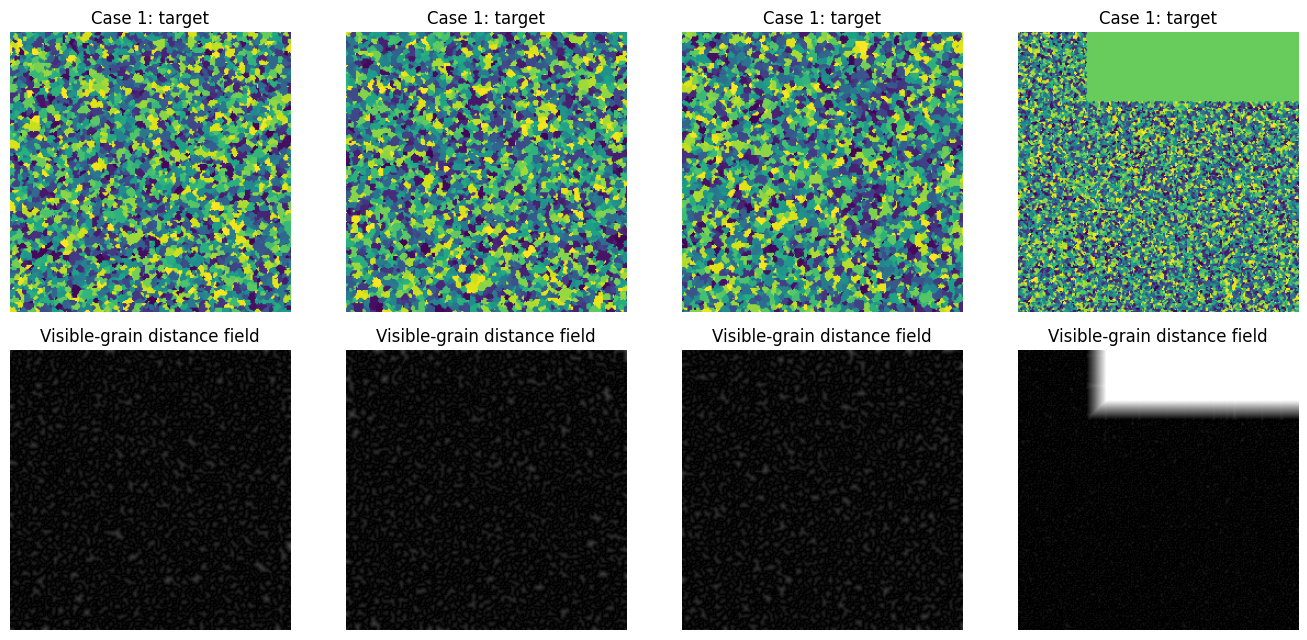

In [12]:
from IPython.display import display, Image as NotebookImage

CONFIG = dict(DEFAULT)
CONFIG.update(
    size=256,
    width=24,
    timesteps=200,
    steps=6000,
    batch_size=2,
    lr=2e-4,
    eval_every=300,
    sample_steps=50,
    quarantine_outliers=True,
)
DATA = prepare(DATA_ROOT, CONFIG)
audit_table = save_audit(DATA, RUN_DIR)
display(audit_table[['case', 'path', 'split', 'edge_fraction', 'quarantined_from_training']])

sample_ids = DATA['train_indices'][:4]
fig, axes = plt.subplots(2, len(sample_ids), figsize=(3.4*len(sample_ids), 6.5), squeeze=False)
for j, idx in enumerate(sample_ids):
    axes[0,j].imshow(DATA['targets'][idx]); axes[0,j].set_title(f"Case {DATA['meta'].iloc[idx].case}: target")
    axes[1,j].imshow(DATA['distance'][idx,0], cmap='gray', vmin=-1, vmax=1)
    axes[1,j].set_title('Visible-grain distance field')
for ax in axes.ravel(): ax.axis('off')
plt.tight_layout(); plt.show()

## 5. Train from scratch or resume

This cell saves `best.pt`, `latest.pt`, and training losses into the run directory. A falling noise MSE does **not** establish image or scientific accuracy. Plan GPU time accordingly.

In [13]:
BEST_CHECKPOINT = train(DATA, CONFIG, RUN_DIR, resume=RESUME)
print('Model ready:', BEST_CHECKPOINT)

Step 1/6000 | train noise MSE 1.1640 | val noise MSE 1.0649 | 0.0 min
Step 300/6000 | train noise MSE 0.0141 | val noise MSE 0.1628 | 0.4 min
Step 600/6000 | train noise MSE 0.0925 | val noise MSE 0.1523 | 0.7 min
Step 900/6000 | train noise MSE 0.0392 | val noise MSE 0.1466 | 1.1 min
Step 1200/6000 | train noise MSE 0.0064 | val noise MSE 0.1447 | 1.4 min
Step 1500/6000 | train noise MSE 0.0521 | val noise MSE 0.1431 | 1.7 min
Step 1800/6000 | train noise MSE 0.0039 | val noise MSE 0.1416 | 2.1 min
Step 2100/6000 | train noise MSE 0.0055 | val noise MSE 0.1409 | 2.4 min
Step 2400/6000 | train noise MSE 0.3565 | val noise MSE 0.1392 | 2.7 min
Step 2700/6000 | train noise MSE 0.0273 | val noise MSE 0.1381 | 3.1 min
Step 3000/6000 | train noise MSE 0.0018 | val noise MSE 0.1373 | 3.4 min
Step 3300/6000 | train noise MSE 0.0097 | val noise MSE 0.1362 | 3.7 min
Step 3600/6000 | train noise MSE 0.0092 | val noise MSE 0.1367 | 4.1 min
Step 3900/6000 | train noise MSE 0.0047 | val noise MSE 0

## 6. **SEE THE IMAGE PREDICTIONS**

Saves `image_predictions_v2.png` and each `case_N_grain_prediction_M.png`. It also exports per-image metrics, summary metrics, edge-density scorecards, and the inferred morphology scale. The rightmost reference is a genuine training image selected without looking at test targets, not a generated prediction.

**Read the image first.** Sharpness and boundary-density statistics are only an initial check; they do not validate true grain IDs, connectivity, material physics, or generalization.

/tmp/ipykernel_688/573876219.py:530: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(rgb.astype('uint8'), 'RGB').save(path)
/tmp/ipykernel_688/573876219.py:530: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(rgb.astype('uint8'), 'RGB').save(path)


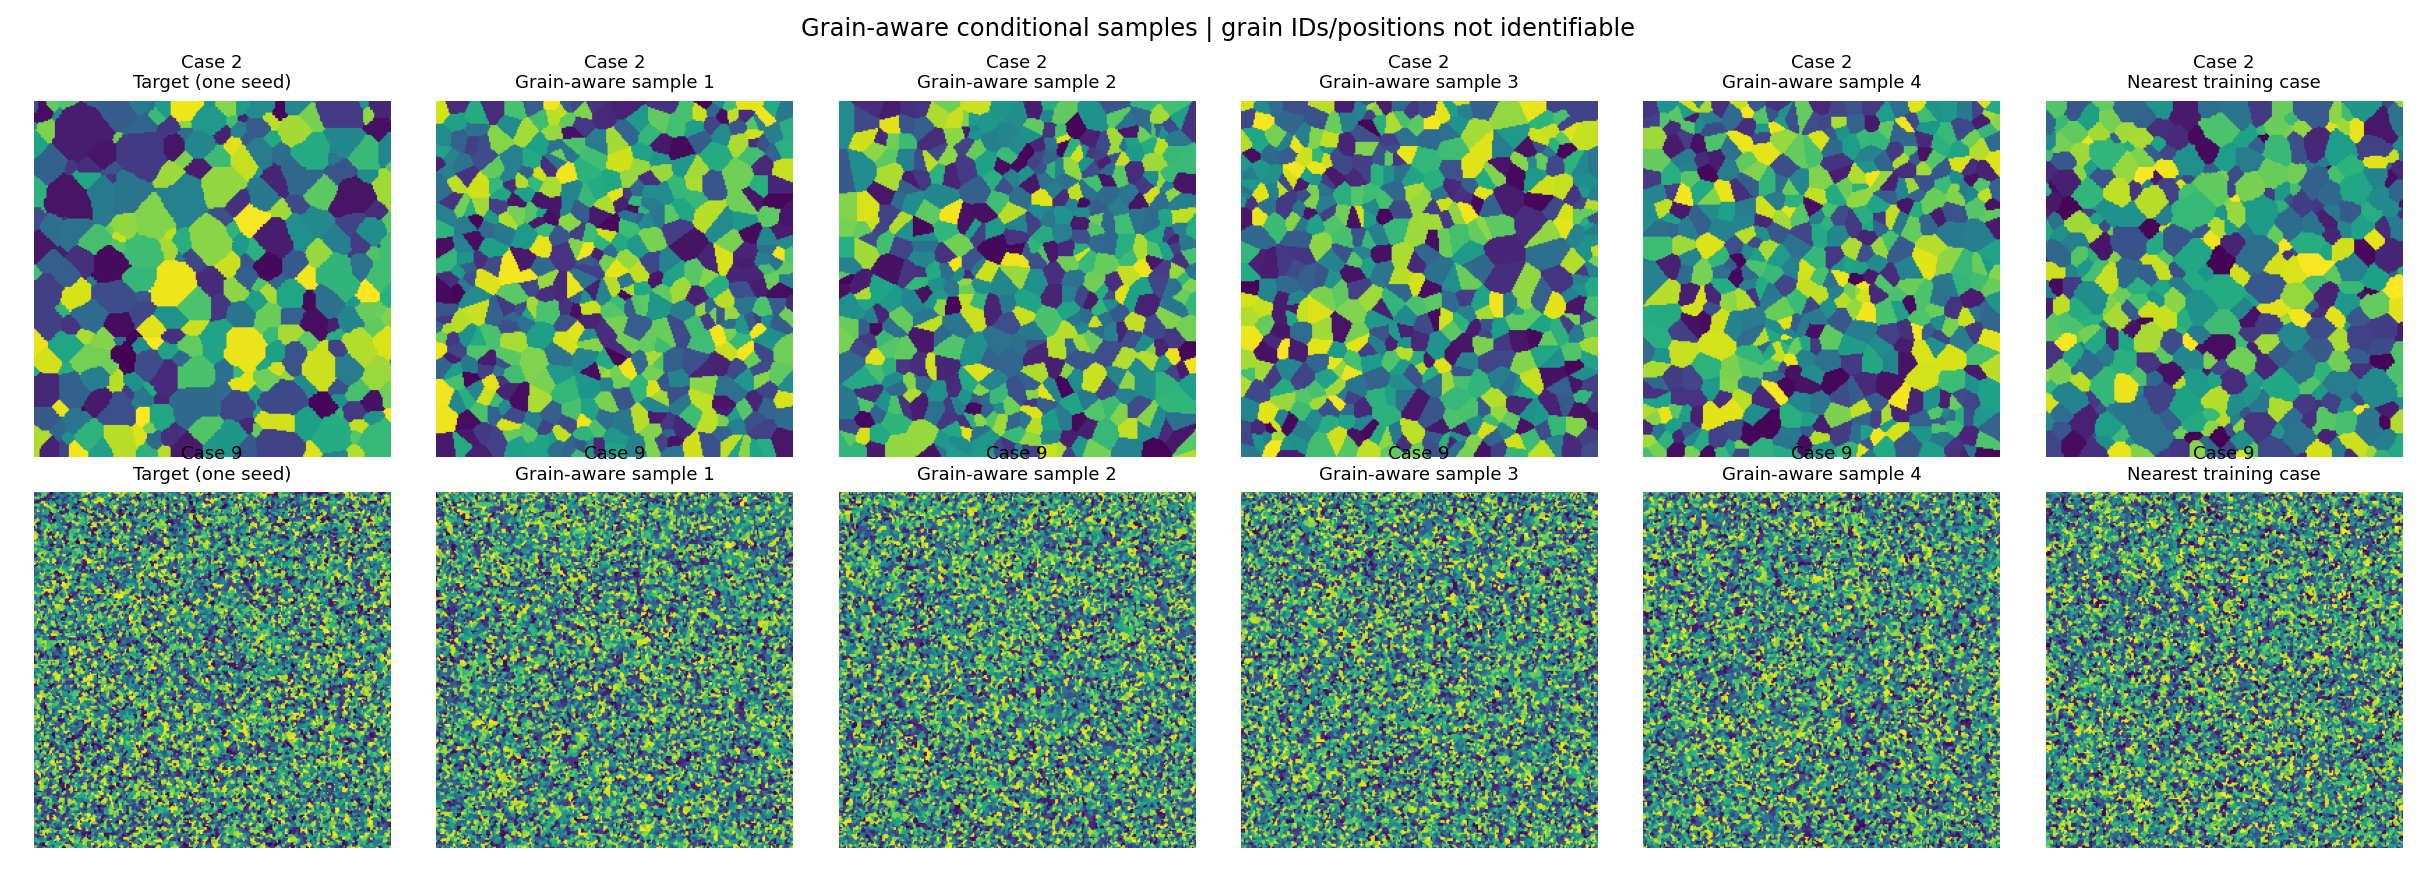

Morphology metrics by case and source:


color_std  edge_fraction  color_difference_lag1  \
case source                                                                   
2    grain_aware_v2            0.2126         0.0900                 0.0241   
     nearest_training_case     0.2065         0.0781                 0.0201   
     target                    0.2184         0.1661                 0.0440   
9    grain_aware_v2            0.2099         0.4589                 0.1194   
     nearest_training_case     0.2137         0.4619                 0.1221   
     target                    0.2140         0.4638                 0.1221   

                            color_difference_lag4  color_difference_lag16  
case source                                                                
2    grain_aware_v2                        0.0919                  0.2271  
     nearest_training_case                 0.0765                  0.2049  
     target                                0.1043                  0.2019  
9    grain_aware_v2                        0.2248                  0.2259  
     nearest_training_case                 0.2281                  0.2282  
     target                                0.2296                  0.2294

Edge-density test scorecard (lower absolute error is better):


,case,source,target_mean_edge_fraction,predicted_mean_edge_fraction,absolute_edge_fraction_error
0,2,grain_aware_v2,0.166058,0.089972,0.076086
1,2,nearest_training_case,0.166058,0.078102,0.087956
2,9,grain_aware_v2,0.463762,0.458871,0.004890
3,9,nearest_training_case,0.463762,0.461941,0.001821


All saved PNGs:
case_2_grain_prediction_1.png
case_2_grain_prediction_2.png
case_2_grain_prediction_3.png
case_2_grain_prediction_4.png
case_9_grain_prediction_1.png
case_9_grain_prediction_2.png
case_9_grain_prediction_3.png
case_9_grain_prediction_4.png


In [14]:
BEST_CHECKPOINT = RUN_DIR / 'best.pt'
summary = evaluate_images(DATA, BEST_CHECKPOINT, RUN_DIR, n_samples=4)
display(NotebookImage(filename=str(RUN_DIR / 'image_predictions_v2.png')))
print('Morphology metrics by case and source:')
display(summary.round(4))
print('Edge-density test scorecard (lower absolute error is better):')
display(pd.read_csv(RUN_DIR / 'edge_density_scorecard.csv'))
print('All saved PNGs:', *(p.name for p in sorted(RUN_DIR.glob('case_*_grain_prediction_*.png'))), sep='\n')

## 7. Training curves and **optional v1-v2 quantitative comparison**

The old `texture_proxies_per_image.csv` supplied with your previous run can be copied to My Drive. The comparison below measures only errors in a display-image edge proxy. It does **not** calculate physical accuracy.

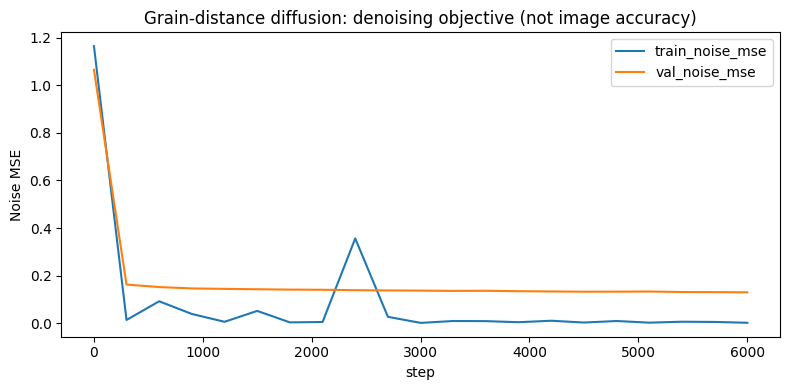

Optional: copy previous texture_proxies_per_image.csv into My Drive for a direct v1-v2 comparison.


In [15]:
history = pd.read_csv(RUN_DIR / 'training_history.csv')
ax = history.plot(x='step', y=['train_noise_mse', 'val_noise_mse'], figsize=(8,4))
ax.set_title('Grain-distance diffusion: denoising objective (not image accuracy)')
ax.set_ylabel('Noise MSE')
plt.tight_layout(); plt.show()

old_path = Path('/content/drive/MyDrive/texture_proxies_per_image.csv')
if old_path.exists():
    old = pd.read_csv(old_path)
    current = pd.read_csv(RUN_DIR / 'morphology_metrics_per_image.csv')
    reports = []
    for label, table, proxy in [
        ('v1 RGB diffusion', old, 'edge_fraction_0.10'),
        ('v2 grain-aware', current, 'edge_fraction'),
    ]:
        for case in sorted(set(current.case) & set(table.case)):
            t = table[(table.case == case) & (table.source == 'target')][proxy].mean()
            genname = 'diffusion' if label.startswith('v1') else 'grain_aware_v2'
            pred = table[(table.case == case) & (table.source == genname)][proxy].mean()
            reports.append(dict(model=label, case=case, target_edge_fraction=t,
                                predicted_edge_fraction=pred, absolute_error=abs(t-pred)))
    display(pd.DataFrame(reports).round(4))
else:
    print('Optional: copy previous texture_proxies_per_image.csv into My Drive for a direct v1-v2 comparison.')

## 8. Predict NEW microstructure images from a thermal CSV + RPM/MPa/dwell

The demonstration uses a held-out case only as the *input*, without passing its target image. Replace `THERMAL_CSV` and the three scalar values for any new process condition. Images appear in `RUN_DIR / "new_predictions"`.

Outputs reflect a *stochastic morphology hypothesis*, not a unique correct grain arrangement. Extrapolation warnings mean prediction is outside the observed process/thermal range.

/tmp/ipykernel_688/573876219.py:605: UserWarning: New process values lie outside training range; extrapolation is unvalidated
  warnings.warn('New process values lie outside training range; extrapolation is unvalidated')
/tmp/ipykernel_688/573876219.py:608: UserWarning: New thermal field exceeds training range
  warnings.warn('New thermal field exceeds training range')
/tmp/ipykernel_688/573876219.py:530: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(rgb.astype('uint8'), 'RGB').save(path)


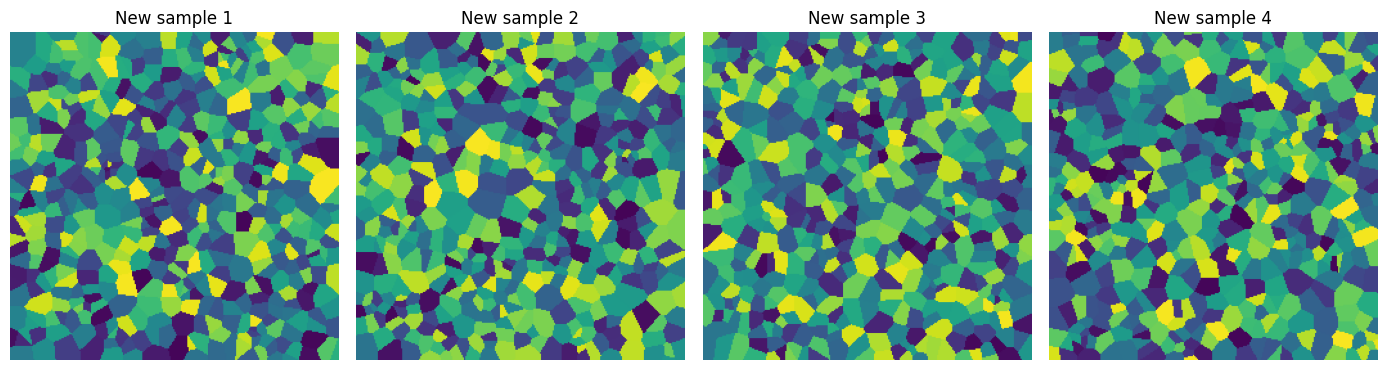

Prediction metadata: /content/drive/MyDrive/VT_grain_aware_runs/run_20261013_011851_732257/new_predictions/prediction_metadata.json


In [16]:
example = DATA['meta'].iloc[DATA['indices']['test'][0]]
THERMAL_CSV = safe_path(DATA_ROOT, example.thermal_history_path)
RPM = float(example.rpm)
MPA = float(example.mpa)
DWELL = float(example.dwell)

images = predict_new(DATA, RUN_DIR/'best.pt', THERMAL_CSV, RPM, MPA, DWELL,
                     RUN_DIR/'new_predictions', n_samples=4, seed=2026)
fig, axs = plt.subplots(1, len(images), figsize=(3.5*len(images), 3.6))
for j, (ax, im) in enumerate(zip(axs, images)):
    ax.imshow(im); ax.axis('off'); ax.set_title(f'New sample {j+1}')
plt.tight_layout(); plt.show()
print('Prediction metadata:', RUN_DIR/'new_predictions'/'prediction_metadata.json')

## Next steps for a scientific model

1. Request uncolored **grain-ID arrays** or neighbor connectivity from the simulation author. Shuffled RGB encodes identity only indirectly; nearby grains can share similar RGB values.
2. Resolve seed 4's different scale and non-square Case 7 domain with simulation settings and coordinate conventions; do not assume they are errors.
3. Acquire substantially more **independent RPM/MPa/dwell + thermal conditions**, preferably with many simulation seeds for each.
4. Evaluate held-out conditions using distributions of labeled-grain areas, equivalent diameters, perimeter/area, number density, orientation, and two-point correlation, with uncertainty intervals. Compare to nearest-case retrieval, a process-only grain-density model, and the original RGB diffusion.
5. Freeze your revised model before collecting a **new test set**. Existing Cases 2 and 9 were inspected while developing v2, so they are exploratory rather than independent confirmatory evidence.

**No model accuracy percentage is claimed in this notebook.** The code has been smoke-tested on a separate synthetic fixture; the original dataset was not available during this revision, so full-scale accuracy and wall-clock time still need to be measured in Colab.